# Notebook 3 — Resultados

**Práctica 3 · Aprendizaje Automático**

Integrantes: Michael Franco, Michael Lata, Jordy Romero, Nayeli Barbecho

Cuaderno de **resultados**: métricas técnicas finales, métricas de negocio,
visualizaciones, el indicador de riesgo por producto y los dos entregables que
consume el resto del proyecto — `metrics/metrics.json` (para la API/CI) y
`reports/reporte_ejecutivo.md` (para una persona no técnica, ej. la cafetería
El Café que te Conté).

## 1. Carga de modelos y datos de test

In [1]:
import json
import sys
import warnings
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from practica3.features import (  # noqa: E402
    FEATURE_COLS,
    HORIZONTES,
    etiquetas_negocio_top_n,
    split_temporal,
)
from practica3.inference import DemandPredictor  # noqa: E402

plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["figure.dpi"] = 110

MODELS_DIR = ROOT / "models"
METRICS_DIR = ROOT / "metrics"
REPORTS_DIR = ROOT / "reports"
METRICS_DIR.mkdir(exist_ok=True)
REPORTS_DIR.mkdir(exist_ok=True)

df = pd.read_parquet(ROOT / "data" / "processed" / "dataset_features.parquet")
features_meta = json.loads((ROOT / "data" / "processed" / "features.json").read_text())
metadata = json.loads((MODELS_DIR / "metadata.json").read_text())
residuales = json.loads((MODELS_DIR / "residuales.json").read_text())
svr_models = {h: joblib.load(MODELS_DIR / f"svr_h{h}.joblib") for h in HORIZONTES}
svc_alerta = joblib.load(MODELS_DIR / "svc_alerta.joblib")
isolation_forest = joblib.load(MODELS_DIR / "isolation_forest.joblib")

# El notebook 2 puede haber descartado features candidatas sin señal real —
# se usa exactamente el conjunto que los modelos guardados esperan.
FEATURE_COLS_MODELO = metadata["feature_cols_modelo"]

# Reconstruye los mismos splits del notebook 2 (determinista, sin aleatoriedad)
splits = {}
for h in HORIZONTES:
    train, test, corte = split_temporal(df, target_col=f"target_h{h}", feature_cols=FEATURE_COLS_MODELO)
    X_test = test[FEATURE_COLS_MODELO].values
    y_test = test[f"target_h{h}"].values
    pred_test = svr_models[h].predict(X_test)
    splits[h] = {"train": train, "test": test, "X_test": X_test, "y_test": y_test, "pred_test": pred_test}

print("Modelos y test sets recargados para horizontes:", HORIZONTES)
print(f"Features usadas por el modelo: {len(FEATURE_COLS_MODELO)} de {len(FEATURE_COLS)} candidatas")

Modelos y test sets recargados para horizontes: (1, 3, 7)
Features usadas por el modelo: 18 de 25 candidatas


## 2. Métricas técnicas finales

Tabla multi-horizonte y comparación en `t+1` contra los dos baselines previos
(Práctica 2 y el Informe SVM), tal como quedaron guardadas por el notebook 2.

In [2]:
tabla_horizontes = pd.DataFrame(metadata["metricas"]).T
tabla_horizontes.index.name = "horizonte"
print("Métricas por horizonte (Práctica 3):")
print(tabla_horizontes.round(3).to_string())

print("\nComparación en t+1:")
comp = pd.DataFrame(metadata["comparacion_baselines_t1"]).T
print(comp.round(3).to_string())

Métricas por horizonte (Práctica 3):
            rmse    mae     r2
horizonte                     
1          5.176  3.621  0.407
3          5.300  3.544  0.365
7          5.016  3.372  0.367

Comparación en t+1:
             rmse_test  mae_test  r2_test   rmse    mae     r2
practica_2       7.125     5.213     0.28    NaN    NaN    NaN
informe_svm        NaN       NaN      NaN  5.110  3.646  0.424
practica_3         NaN       NaN      NaN  5.176  3.621  0.407


## 3. Real vs predicho, por horizonte

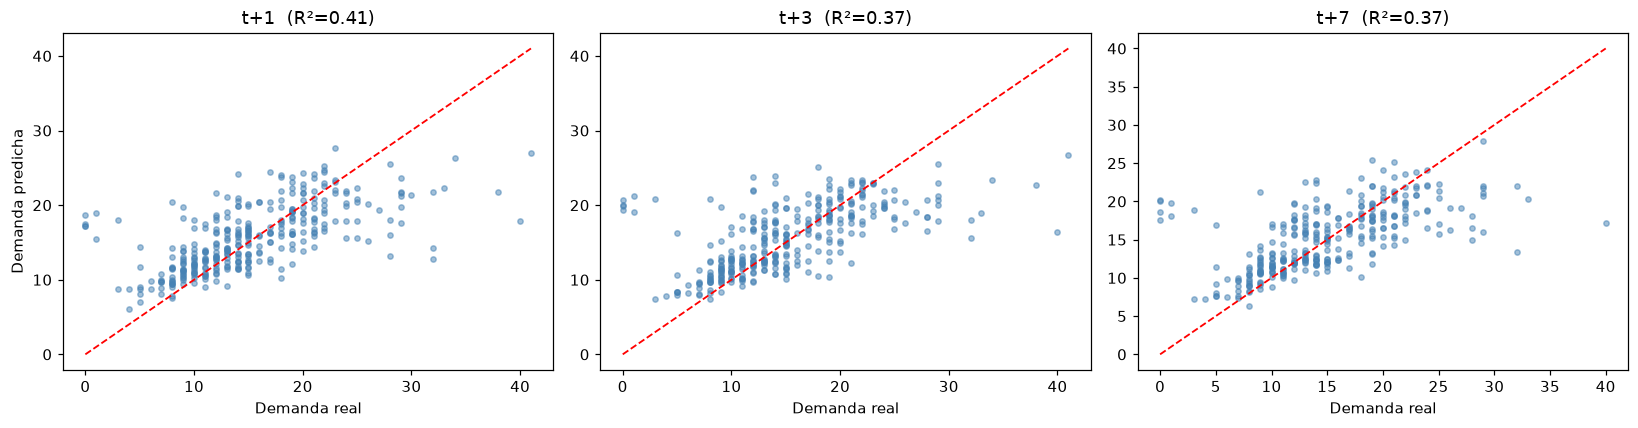

In [3]:
fig, axes = plt.subplots(1, len(HORIZONTES), figsize=(5 * len(HORIZONTES), 4))
for ax, h in zip(axes, HORIZONTES):
    y_true, y_pred = splits[h]["y_test"], splits[h]["pred_test"]
    ax.scatter(y_true, y_pred, s=12, alpha=0.5, color="steelblue")
    lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    ax.plot(lims, lims, "r--", lw=1.2)
    r2 = metadata["metricas"][str(h)]["r2"]
    ax.set_title(f"t+{h}  (R²={r2:.2f})")
    ax.set_xlabel("Demanda real"); ax.set_ylabel("Demanda predicha" if h == HORIZONTES[0] else "")
plt.tight_layout(); plt.show()

## 4. Serie temporal con escenarios (producto top, horizonte t+1)

Demanda real vs predicha del producto más vendido en el periodo de test, con la
banda **conservador–optimista** calculada en el notebook 2 (§V.D del feedback:
"mostrar intervalos de confianza" y "escenarios optimista/esperado/conservador").

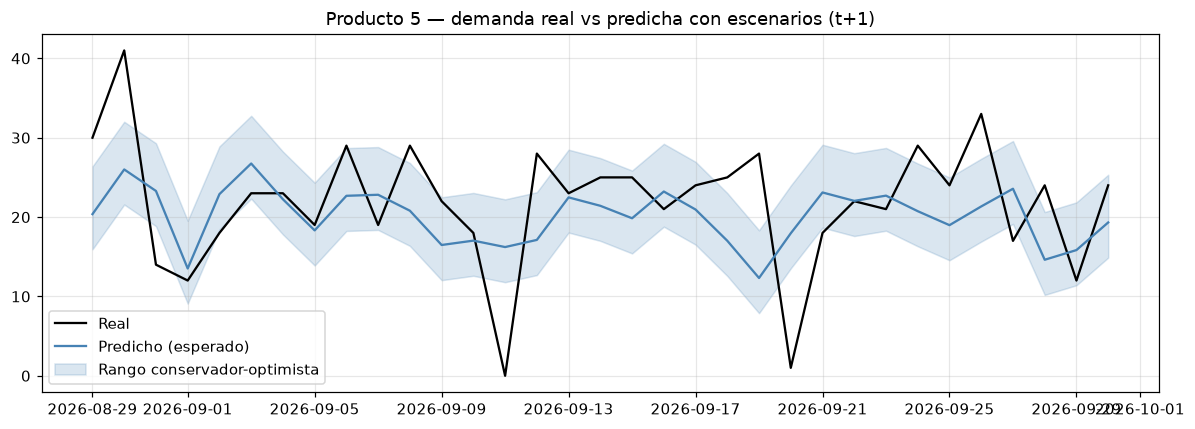

In [4]:
predictor = DemandPredictor()

test_h1 = splits[1]["test"]
pid_top = test_h1.groupby("product_id")["cantidad_vendida"].sum().idxmax()
fechas_top = test_h1[test_h1["product_id"] == pid_top].sort_values("fecha")["fecha"]

registros = [predictor.predecir(int(pid_top), str(f.date()), horizonte=1) for f in fechas_top]
serie = pd.DataFrame(registros)
reales = test_h1[test_h1["product_id"] == pid_top].sort_values("fecha").set_index("fecha")["target_h1"]
serie = serie.set_index(pd.to_datetime(serie["fecha_referencia_datos"]))

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(reales.index, reales.values, label="Real", color="black", lw=1.5)
ax.plot(serie.index, serie["prediccion_esperada"], label="Predicho (esperado)", color="steelblue", lw=1.5)
ax.fill_between(serie.index, serie["escenario_conservador"], serie["escenario_optimista"],
                color="steelblue", alpha=0.2, label="Rango conservador-optimista")
ax.set_title(f"Producto {pid_top} — demanda real vs predicha con escenarios (t+1)")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 5. Métricas de negocio — impacto económico estimado

Punto §V.1 del feedback: métricas orientadas al negocio, no solo técnicas. Se asigna
un **costo unitario ilustrativo por categoría** (quiebre de stock vs sobre-stock) —
son valores de ejemplo, parametrizables; se reemplazarán por los reales cuando llegue
el Excel de la empresa. Se compara contra un baseline ingenuo (`lag_7`: "lo mismo que
hace una semana") para cuantificar cuánto ahorra usar el modelo.

In [5]:
COSTO_QUIEBRE_POR_UNIDAD = {"Electronica": 25.0, "Perifericos": 8.0, "Accesorios": 4.0, "Cables": 2.0}
COSTO_SOBRESTOCK_POR_UNIDAD = {"Electronica": 6.0, "Perifericos": 2.0, "Accesorios": 1.0, "Cables": 0.5}

test_h1 = splits[1]["test"].copy()
test_h1["pred"] = splits[1]["pred_test"]
test_h1["pred_naive"] = test_h1["lag_7"]  # baseline: demanda de hace 7 dias

def costo_total(df_, col_pred):
    quiebre = (df_["target_h1"] - df_[col_pred]).clip(lower=0) * df_["categoria"].map(COSTO_QUIEBRE_POR_UNIDAD)
    sobre = (df_[col_pred] - df_["target_h1"]).clip(lower=0) * df_["categoria"].map(COSTO_SOBRESTOCK_POR_UNIDAD)
    return float(quiebre.sum()), float(sobre.sum())

quiebre_modelo, sobre_modelo = costo_total(test_h1, "pred")
quiebre_naive, sobre_naive = costo_total(test_h1, "pred_naive")

resumen_negocio = pd.DataFrame([
    {"escenario": "Baseline ingenuo (lag_7)", "costo_quiebre": quiebre_naive, "costo_sobrestock": sobre_naive,
     "costo_total": quiebre_naive + sobre_naive},
    {"escenario": "Modelo Práctica 3 (SVR t+1)", "costo_quiebre": quiebre_modelo, "costo_sobrestock": sobre_modelo,
     "costo_total": quiebre_modelo + sobre_modelo},
]).round(2)
reduccion_pct = 100 * (1 - resumen_negocio.loc[1, "costo_total"] / resumen_negocio.loc[0, "costo_total"])
print(resumen_negocio.to_string(index=False))
print(f"\nReducción de costo estimado usando el modelo vs baseline ingenuo: {reduccion_pct:.1f}%")
print("(costos unitarios ilustrativos — ver docs/02_glosario.md)")

                  escenario  costo_quiebre  costo_sobrestock  costo_total
   Baseline ingenuo (lag_7)        5547.00           1635.50       7182.5
Modelo Práctica 3 (SVR t+1)        2782.23           1230.77       4013.0

Reducción de costo estimado usando el modelo vs baseline ingenuo: 44.1%
(costos unitarios ilustrativos — ver docs/02_glosario.md)


## 6. Detección de anomalías — resumen en test

In [6]:
pred_anom = isolation_forest.predict(splits[1]["X_test"])
test_h1["anomalia"] = pred_anom == -1
n_anom = int(test_h1["anomalia"].sum())
print(f"Compras/ventas marcadas como atípicas en test: {n_anom} / {len(test_h1)} ({n_anom/len(test_h1):.1%})")
cols = ["fecha", "product_id", "nombre", "cantidad_vendida", "target_h1", "pred"]
test_h1[test_h1["anomalia"]][cols].sort_values("fecha").head(10)

Compras/ventas marcadas como atípicas en test: 15 / 330 (4.5%)


,fecha,product_id,nombre,cantidad_vendida,target_h1,pred
19,2026-08-30,10,Cargador Rapido,20,34.0,26.284051
25,2026-08-31,10,Cargador Rapido,34,20.0,24.269625
28,2026-08-31,5,Cable USB-C,41,14.0,24.218557
31,2026-09-01,5,Cable USB-C,14,12.0,14.452069
57,2026-09-03,5,Cable USB-C,18,23.0,27.674338
88,2026-09-06,10,Cargador Rapido,19,22.0,20.082063
142,2026-09-12,10,Cargador Rapido,40,17.0,15.047427
157,2026-09-13,5,Cable USB-C,28,23.0,23.405083
167,2026-09-14,10,Cargador Rapido,0,22.0,25.205152
211,2026-09-19,10,Cargador Rapido,24,22.0,22.506543


## 7. Importancia de variables — resumen final

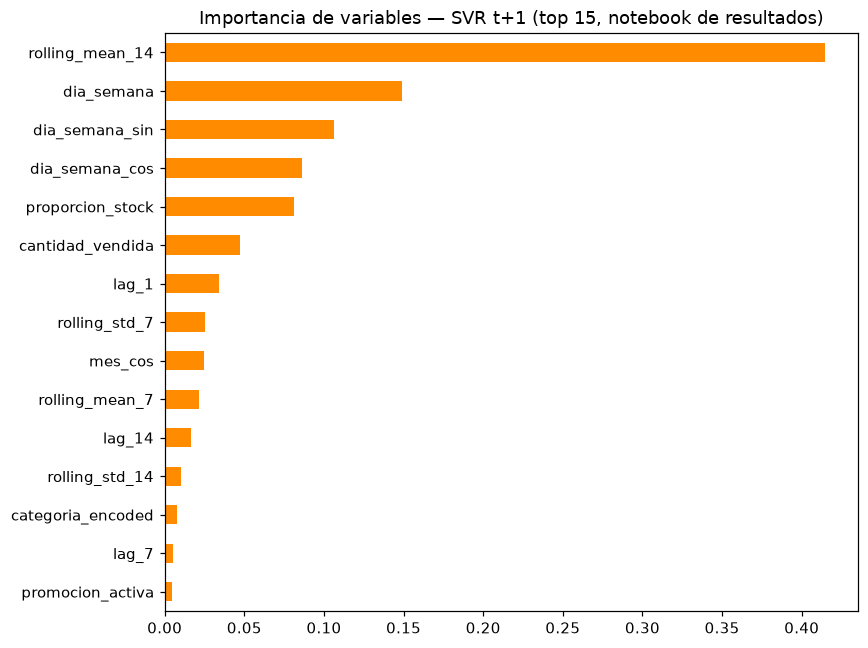

Top 5 variables más influyentes:
  rolling_mean_14           0.4146
  dia_semana                0.1487
  dia_semana_sin            0.1064
  dia_semana_cos            0.0860
  proporcion_stock          0.0812


In [7]:
perm = permutation_importance(
    svr_models[1], splits[1]["X_test"], splits[1]["y_test"], n_repeats=20, random_state=42, n_jobs=-1
)
importancia = pd.Series(perm.importances_mean, index=FEATURE_COLS_MODELO).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
importancia.head(15).iloc[::-1].plot.barh(ax=ax, color="darkorange")
ax.set_title("Importancia de variables — SVR t+1 (top 15, notebook de resultados)")
plt.tight_layout(); plt.show()

top5 = importancia.head(5)
print("Top 5 variables más influyentes:")
for nombre, val in top5.items():
    print(f"  {nombre:25s} {val:.4f}")

## 8. Indicador de riesgo — semáforo por producto

Punto §V.7 del feedback: un indicador fácil de interpretar. Para cada producto se
calcula la predicción de mañana (t+1) a partir de su última fecha disponible, con su
nivel de riesgo (verde/amarillo/rojo) según ancho del intervalo y calidad de datos.

In [8]:
EMOJI_RIESGO = {"verde": "🟢", "amarillo": "🟡", "rojo": "🔴"}
fecha_max = df["fecha"].max()
semaforo = []
for pid in sorted(df["product_id"].unique()):
    r = predictor.predecir(int(pid), str(fecha_max.date()), horizonte=1)
    nombre = df.loc[df["product_id"] == pid, "nombre"].iloc[0]
    semaforo.append({
        "product_id": pid, "nombre": nombre,
        "prediccion_manana": r["prediccion_esperada"],
        "rango": f"{r['escenario_conservador']}–{r['escenario_optimista']}",
        "nivel_riesgo": r["nivel_riesgo"],
        "riesgo": EMOJI_RIESGO[r["nivel_riesgo"]] + " " + r["nivel_riesgo"],
        "alerta_alta_demanda": r["alerta_alta_demanda"],
    })
semaforo_df = pd.DataFrame(semaforo)
print(semaforo_df.drop(columns=["nivel_riesgo"]).to_string(index=False))

 product_id           nombre  prediccion_manana       rango     riesgo  alerta_alta_demanda
          1     Laptop Gamer              11.30  6.87–17.31 🟡 amarillo                False
          2       Monitor 4K              13.21  8.78–19.22 🟡 amarillo                False
          3 Teclado Mecanico              15.25 10.82–21.26 🟡 amarillo                 True
          4      Raton Inal.              16.28 11.85–22.29 🟡 amarillo                False
          5      Cable USB-C              19.99  15.56–26.0 🟡 amarillo                False
          6   Adaptador HDMI              16.99  12.57–23.0 🟡 amarillo                False
          7        Webcam HD              11.82   7.4–17.83 🟡 amarillo                False
          8   Auriculares BT              15.64 11.22–21.65 🟡 amarillo                False
          9      Hub USB 3.0              10.58  6.16–16.59 🟡 amarillo                False
         10  Cargador Rapido              16.57 12.14–22.58 🟡 amarillo          

## 9. `metrics/metrics.json` — métricas ordenadas

In [9]:
metrics_json = {
    "proyecto": "Practica_3 - Prediccion de demanda (SVR multi-horizonte)",
    "generado_en": datetime.now().isoformat(timespec="seconds"),
    "dataset": {
        "origen": "sintetico (Practica_2, reutilizado sin cambios)",
        "n_productos": int(df["product_id"].nunique()),
        "n_dias": int(df["fecha"].nunique()),
        "n_features_candidatas": len(FEATURE_COLS),
        "n_features_modelo": len(FEATURE_COLS_MODELO),
    },
    "metricas_tecnicas_por_horizonte": metadata["metricas"],
    "comparacion_baselines_t1": metadata["comparacion_baselines_t1"],
    "clasificador_alerta_alta_demanda": metadata["svc_alerta"],
    "deteccion_anomalias": {
        "contamination": metadata["isolation_forest"]["contamination"],
        "n_anomalias_test": n_anom,
        "pct_anomalias_test": round(n_anom / len(test_h1), 4),
    },
    "metricas_negocio_t1": {
        "costo_estimado_baseline_ingenuo": resumen_negocio.loc[0, "costo_total"],
        "costo_estimado_modelo": resumen_negocio.loc[1, "costo_total"],
        "reduccion_costo_pct": round(reduccion_pct, 2),
        "nota": "costos unitarios ilustrativos, ver docs/02_glosario.md",
    },
    "importancia_variables_top5": top5.round(4).to_dict(),
    "features_descartadas_en_seleccion": metadata["features_descartadas"],
    "semaforo_riesgo_actual": semaforo_df.drop(columns=["riesgo"]).to_dict("records"),
}

with open(METRICS_DIR / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics_json, f, indent=2, ensure_ascii=False)

print("Guardado: metrics/metrics.json")
print(json.dumps(metrics_json["metricas_tecnicas_por_horizonte"], indent=2))

Guardado: metrics/metrics.json
{
  "1": {
    "rmse": 5.1762,
    "mae": 3.6212,
    "r2": 0.4073
  },
  "3": {
    "rmse": 5.3005,
    "mae": 3.5436,
    "r2": 0.3654
  },
  "7": {
    "rmse": 5.0156,
    "mae": 3.3717,
    "r2": 0.367
  }
}


## 10. Reporte ejecutivo (no técnico)

Punto §V.6 del feedback: reportes automáticos dirigidos a usuarios empresariales,
en lenguaje simple — pensado para alguien como el equipo de El Café que te Conté,
sin necesidad de entender SVR, R² ni intervalos de confianza.

In [10]:
lineas = []
lineas.append("# Reporte ejecutivo de demanda\n\n")
lineas.append(f"_Generado automáticamente el {datetime.now():%Y-%m-%d %H:%M}_\n\n")
lineas.append(
    "Este reporte resume, en lenguaje simple, qué tan bien predice el sistema la "
    "demanda de cada producto y qué se espera para mañana.\n\n"
)
lineas.append("## ¿Qué tan confiable es el sistema?\n\n")
r2_t1 = metadata['metricas']['1']['r2']
lineas.append(
    f"- En promedio, el modelo explica **{r2_t1:.0%}** de las variaciones de la demanda del día "
    "siguiente (antes de esta mejora explicaba un 28%).\n"
    f"- Usar el modelo, en vez de simplemente repetir la venta de la semana pasada, "
    f"reduciría el costo estimado por quiebres de stock y sobre-stock en un **{reduccion_pct:.0f}%** "
    "(con costos de ejemplo — se ajustará con datos reales de la empresa).\n\n"
)
lineas.append("## Predicción para mañana, por producto\n\n")
lineas.append("| Producto | Predicción | Rango esperado | Riesgo | Alerta alta demanda |\n")
lineas.append("|---|---|---|---|---|\n")
for row in semaforo:
    lineas.append(
        f"| {row['nombre']} | {row['prediccion_manana']:.0f} u. | {row['rango']} u. | "
        f"{row['riesgo']} | {'Sí' if row['alerta_alta_demanda'] else 'No'} |\n"
    )
lineas.append("\n## ¿Qué mueve más la predicción?\n\n")
for etiqueta in etiquetas_negocio_top_n(importancia, n=5):
    lineas.append(f"- {etiqueta}\n")
lineas.append(
    "\n## Limitaciones actuales\n\n"
    "- Los datos son **sintéticos** (no son las ventas reales del negocio todavía).\n"
    "- Variables como promociones o clima son simuladas; con el Excel real de la "
    "empresa se recalcularán y probablemente su importancia cambie.\n"
    f"- Productos marcados en 🔴 no tienen suficiente historial (mínimo "
    f"{features_meta['min_dias_historicos']} días) — sus predicciones son menos confiables.\n"
)

reporte_md = "".join(lineas)
(REPORTS_DIR / "reporte_ejecutivo.md").write_text(reporte_md, encoding="utf-8")
print(f"Guardado: reports/reporte_ejecutivo.md ({len(reporte_md.splitlines())} líneas)")
print(reporte_md)

Guardado: reports/reporte_ejecutivo.md (39 líneas)
# Reporte ejecutivo de demanda

_Generado automáticamente el 2026-07-08 17:14_

Este reporte resume, en lenguaje simple, qué tan bien predice el sistema la demanda de cada producto y qué se espera para mañana.

## ¿Qué tan confiable es el sistema?

- En promedio, el modelo explica **41%** de las variaciones de la demanda del día siguiente (antes de esta mejora explicaba un 28%).
- Usar el modelo, en vez de simplemente repetir la venta de la semana pasada, reduciría el costo estimado por quiebres de stock y sobre-stock en un **44%** (con costos de ejemplo — se ajustará con datos reales de la empresa).

## Predicción para mañana, por producto

| Producto | Predicción | Rango esperado | Riesgo | Alerta alta demanda |
|---|---|---|---|---|
| Laptop Gamer | 11 u. | 6.87–17.31 u. | 🟡 amarillo | No |
| Monitor 4K | 13 u. | 8.78–19.22 u. | 🟡 amarillo | No |
| Teclado Mecanico | 15 u. | 10.82–21.26 u. | 🟡 amarillo | Sí |
| Raton Inal. | 16 u. |

## Conclusiones

- El SVR de horizonte t+1 de esta práctica queda documentado en `metrics/metrics.json`,
  comparado formalmente contra Práctica 2 (R²=0.28) y el Informe SVM (R²≈0.42).
- Se entregan los 7 puntos de mejora de `Feedback Empresas.pdf` §V: horizontes
  múltiples, intervalos/escenarios, importancia de variables, anomalías, métricas de
  negocio, reporte automático no técnico e indicador de riesgo fácil de leer.
- `reports/reporte_ejecutivo.md` y `metrics/metrics.json` son los artefactos que
  consumirían un usuario de negocio y la API/CI respectivamente — ambos se generan
  automáticamente al correr `make pipeline`.